# Notebook 2: Data Preprocessing

This notebook focuses on preparing the Alzheimer's disease dataset for machine learning. Proper preprocessing is essential for building accurate and reliable models. We will handle missing values, remove unnecessary columns, scale features, and address class imbalance.

The preprocessing steps we perform here will ensure that our data is clean, normalized, and balanced, setting a solid foundation for the model building phase.

## Loading Required Libraries

We import the necessary libraries for data manipulation, preprocessing, and handling class imbalance. The scikit-learn library provides tools for data splitting and scaling, while imbalanced-learn provides SMOTE for oversampling the minority class.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

## Loading the Dataset

We load the same dataset that we explored in the previous notebook. This ensures consistency across our analysis pipeline.

In [2]:
df = pd.read_csv('alzheimers_disease_data.csv')
print("Dataset loaded successfully!")
print(f"Shape: {df.shape}")

Dataset loaded successfully!
Shape: (2149, 35)


## Checking for Missing Values

Before proceeding with any transformations, we verify that there are no missing values in the dataset. Missing values can cause errors during model training and may need imputation or removal.

In [3]:
missing_count = df.isnull().sum().sum()
print(f"Total missing values: {missing_count}")

if missing_count == 0:
    print("The dataset has no missing values. No imputation needed.")
else:
    print("Missing values found. Handling required.")
    print(df.isnull().sum()[df.isnull().sum() > 0])

Total missing values: 0
The dataset has no missing values. No imputation needed.


## Removing Non-Feature Columns

The dataset contains two columns that are not useful for prediction: PatientID (a unique identifier) and DoctorInCharge (administrative information). These columns do not contribute to the prediction of Alzheimer's disease and should be removed before modeling.

In [4]:
columns_to_remove = ['PatientID', 'DoctorInCharge']
df_processed = df.copy()

for col in columns_to_remove:
    if col in df_processed.columns:
        df_processed = df_processed.drop(col, axis=1)
        print(f"Removed column: {col}")

print(f"\nShape after removal: {df_processed.shape}")
print(f"Remaining columns: {df_processed.shape[1]}")

Removed column: PatientID
Removed column: DoctorInCharge

Shape after removal: (2149, 33)
Remaining columns: 33


## Separating Features and Target Variable

We separate the dataset into features (X) and the target variable (y). The target variable is 'Diagnosis', which indicates whether a patient has Alzheimer's disease. All other columns will be used as features for prediction.

In [5]:
X = df_processed.drop('Diagnosis', axis=1)
y = df_processed['Diagnosis']

print("Features and target separated successfully!")
print(f"\nNumber of features: {X.shape[1]}")
print(f"Number of samples: {X.shape[0]}")
print(f"\nFeature names:")
for i, col in enumerate(X.columns, 1):
    print(f"  {i:2}. {col}")

Features and target separated successfully!

Number of features: 32
Number of samples: 2149

Feature names:
   1. Age
   2. Gender
   3. Ethnicity
   4. EducationLevel
   5. BMI
   6. Smoking
   7. AlcoholConsumption
   8. PhysicalActivity
   9. DietQuality
  10. SleepQuality
  11. FamilyHistoryAlzheimers
  12. CardiovascularDisease
  13. Diabetes
  14. Depression
  15. HeadInjury
  16. Hypertension
  17. SystolicBP
  18. DiastolicBP
  19. CholesterolTotal
  20. CholesterolLDL
  21. CholesterolHDL
  22. CholesterolTriglycerides
  23. MMSE
  24. FunctionalAssessment
  25. MemoryComplaints
  26. BehavioralProblems
  27. ADL
  28. Confusion
  29. Disorientation
  30. PersonalityChanges
  31. DifficultyCompletingTasks
  32. Forgetfulness


## Target Variable Distribution

Let us examine the current distribution of the target variable. This is important because class imbalance can negatively affect model performance, causing the model to be biased toward the majority class.

In [6]:
print("Target Variable Distribution:")
print("="*50)
print(y.value_counts())
print(f"\nClass 0 (No Alzheimer's): {(y == 0).sum()} ({(y == 0).mean()*100:.1f}%)")
print(f"Class 1 (Alzheimer's):    {(y == 1).sum()} ({(y == 1).mean()*100:.1f}%)")

Target Variable Distribution:
Diagnosis
0    1389
1     760
Name: count, dtype: int64

Class 0 (No Alzheimer's): 1389 (64.6%)
Class 1 (Alzheimer's):    760 (35.4%)


## Splitting Data into Training and Testing Sets

We divide the data into training and testing sets using an 80-20 split. The training set will be used to train our models, while the testing set will be used for final evaluation. We use stratified sampling to maintain the same class distribution in both sets.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Data Split Summary:")
print("="*50)
print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"Testing set:  {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.0f}%)")
print(f"\nTraining set class distribution:")
print(y_train.value_counts())
print(f"\nTesting set class distribution:")
print(y_test.value_counts())

Data Split Summary:
Training set: 1719 samples (80%)
Testing set:  430 samples (20%)

Training set class distribution:
Diagnosis
0    1111
1     608
Name: count, dtype: int64

Testing set class distribution:
Diagnosis
0    278
1    152
Name: count, dtype: int64


## Feature Scaling with StandardScaler

Many machine learning algorithms perform better when features are on a similar scale. StandardScaler transforms features to have zero mean and unit variance. This is particularly important for algorithms like Support Vector Machines and k-Nearest Neighbors that are sensitive to feature magnitudes.

We fit the scaler only on the training data to prevent information leakage from the test set. The same transformation is then applied to the test set.

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Complete!")
print("="*50)
print(f"Scaled training set shape: {X_train_scaled.shape}")
print(f"Scaled testing set shape:  {X_test_scaled.shape}")
print(f"\nTraining data statistics after scaling:")
print(f"  Mean (approx): {X_train_scaled.mean():.6f}")
print(f"  Std (approx):  {X_train_scaled.std():.6f}")

Feature Scaling Complete!
Scaled training set shape: (1719, 32)
Scaled testing set shape:  (430, 32)

Training data statistics after scaling:
  Mean (approx): -0.000000
  Std (approx):  1.000000


## Handling Class Imbalance with SMOTE

SMOTE (Synthetic Minority Over-sampling Technique) addresses the class imbalance problem by creating synthetic samples of the minority class. Instead of simply duplicating existing samples, SMOTE generates new samples by interpolating between existing minority class samples.

We apply SMOTE only to the training data. The test set remains unchanged to provide an unbiased evaluation of model performance on real data distribution.

In [9]:
print("Before SMOTE:")
print(f"  Training samples: {X_train_scaled.shape[0]}")
print(f"  Class distribution: {Counter(y_train)}")

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print("\nAfter SMOTE:")
print(f"  Training samples: {X_train_balanced.shape[0]}")
print(f"  Class distribution: {Counter(y_train_balanced)}")
print(f"\nNew samples created: {X_train_balanced.shape[0] - X_train_scaled.shape[0]}")

Before SMOTE:
  Training samples: 1719
  Class distribution: Counter({0: 1111, 1: 608})

After SMOTE:
  Training samples: 2222
  Class distribution: Counter({0: 1111, 1: 1111})

New samples created: 503


  File "C:\Users\pendy\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\pendy\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pendy\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pendy\anaconda3\Lib\subprocess.

## Visualizing Class Distribution Before and After SMOTE

This visualization clearly shows how SMOTE balances the classes by creating synthetic samples for the minority class. After SMOTE, both classes have equal representation in the training data.

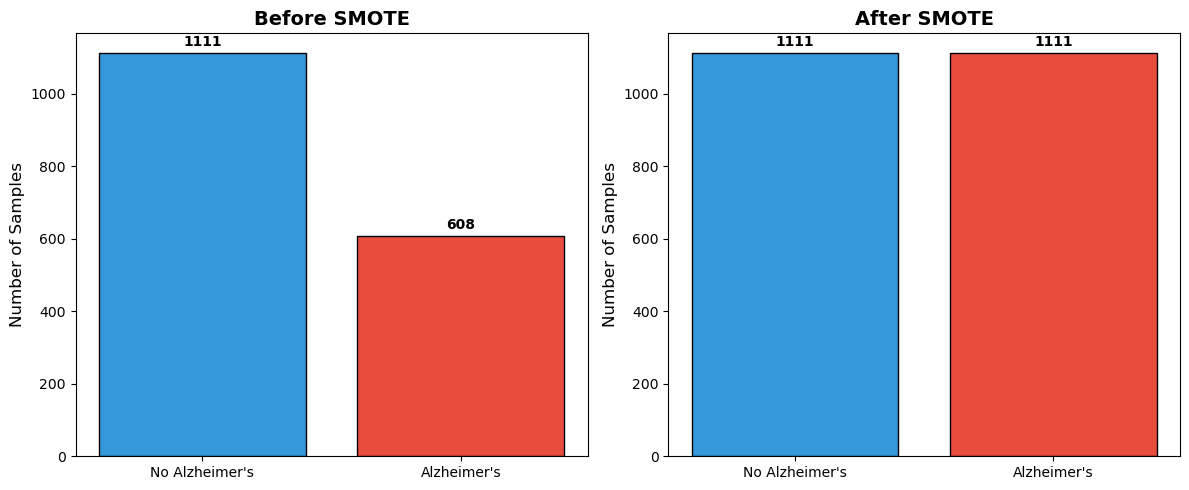

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

before_counts = pd.Series(y_train).value_counts().sort_index()
axes[0].bar(['No Alzheimer\'s', 'Alzheimer\'s'], before_counts.values, 
            color=['#3498db', '#e74c3c'], edgecolor='black')
axes[0].set_ylabel('Number of Samples', fontsize=12)
axes[0].set_title('Before SMOTE', fontsize=14, fontweight='bold')
for i, v in enumerate(before_counts.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

after_counts = pd.Series(y_train_balanced).value_counts().sort_index()
axes[1].bar(['No Alzheimer\'s', 'Alzheimer\'s'], after_counts.values, 
            color=['#3498db', '#e74c3c'], edgecolor='black')
axes[1].set_ylabel('Number of Samples', fontsize=12)
axes[1].set_title('After SMOTE', fontsize=14, fontweight='bold')
for i, v in enumerate(after_counts.values):
    axes[1].text(i, v + 20, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## Saving Preprocessed Data

We save the preprocessed data to files so that subsequent notebooks can use them without repeating the preprocessing steps. This ensures consistency across our analysis pipeline.

In [11]:
np.save('X_train_balanced.npy', X_train_balanced)
np.save('y_train_balanced.npy', y_train_balanced)
np.save('X_test_scaled.npy', X_test_scaled)
np.save('y_test.npy', y_test)

feature_names = X.columns.tolist()
pd.DataFrame({'feature_name': feature_names}).to_csv('feature_names.csv', index=False)

print("Preprocessed data saved successfully!")
print("="*50)
print("Files created:")
print("  - X_train_balanced.npy")
print("  - y_train_balanced.npy")
print("  - X_test_scaled.npy")
print("  - y_test.npy")
print("  - feature_names.csv")

Preprocessed data saved successfully!
Files created:
  - X_train_balanced.npy
  - y_train_balanced.npy
  - X_test_scaled.npy
  - y_test.npy
  - feature_names.csv


## Preprocessing Summary

Here is a summary of all the preprocessing steps performed:

In [12]:
print("\n" + "="*60)
print("PREPROCESSING SUMMARY")
print("="*60)
print("\n1. Missing Values: None found")
print("\n2. Removed Columns:")
print("   - PatientID (identifier, not predictive)")
print("   - DoctorInCharge (administrative, not predictive)")
print(f"\n3. Features Used: {len(feature_names)} (all available features)")
print(f"\n4. Data Split:")
print(f"   - Training: {X_train.shape[0]} samples (80%)")
print(f"   - Testing:  {X_test.shape[0]} samples (20%)")
print(f"\n5. Feature Scaling: StandardScaler applied")
print(f"   - Mean: 0, Standard Deviation: 1")
print(f"\n6. Class Balancing: SMOTE applied to training data")
print(f"   - Before: {dict(Counter(y_train))}")
print(f"   - After:  {dict(Counter(y_train_balanced))}")
print("\n" + "="*60)
print("Ready for model building in Notebook 3!")
print("="*60)


PREPROCESSING SUMMARY

1. Missing Values: None found

2. Removed Columns:
   - PatientID (identifier, not predictive)
   - DoctorInCharge (administrative, not predictive)

3. Features Used: 32 (all available features)

4. Data Split:
   - Training: 1719 samples (80%)
   - Testing:  430 samples (20%)

5. Feature Scaling: StandardScaler applied
   - Mean: 0, Standard Deviation: 1

6. Class Balancing: SMOTE applied to training data
   - Before: {0: 1111, 1: 608}
   - After:  {0: 1111, 1: 1111}

Ready for model building in Notebook 3!
